 Скачиваем датасет и копируем его в проект

In [3]:
import kagglehub
import shutil
from pathlib import Path

path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
print("Path to dataset files:", path)

# копируем CSV в папку проекта
dest = Path("../data/raw")
dest.mkdir(parents=True, exist_ok=True)

for file in Path(path).glob("*.csv"):
    shutil.copy(file, dest / file.name)
    print("Скопировано:", file.name)

Path to dataset files: /Users/taisiabogatyreva/.cache/kagglehub/datasets/jessemostipak/hotel-booking-demand/versions/1
Скопировано: hotel_bookings.csv


Проверяем что данные читаются

In [4]:
import pandas as pd

df = pd.read_csv("../data/raw/hotel_bookings.csv")
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


📊 Размер датасета: 119390 строк, 32 колонок

--- Пропущенные значения (Missing Values) ---
children         4
country        488
agent        16340
company     112593
dtype: int64

--- Распределение целевого класса (is_canceled), % ---
is_canceled
0    63.0
1    37.0
Name: proportion, dtype: float64


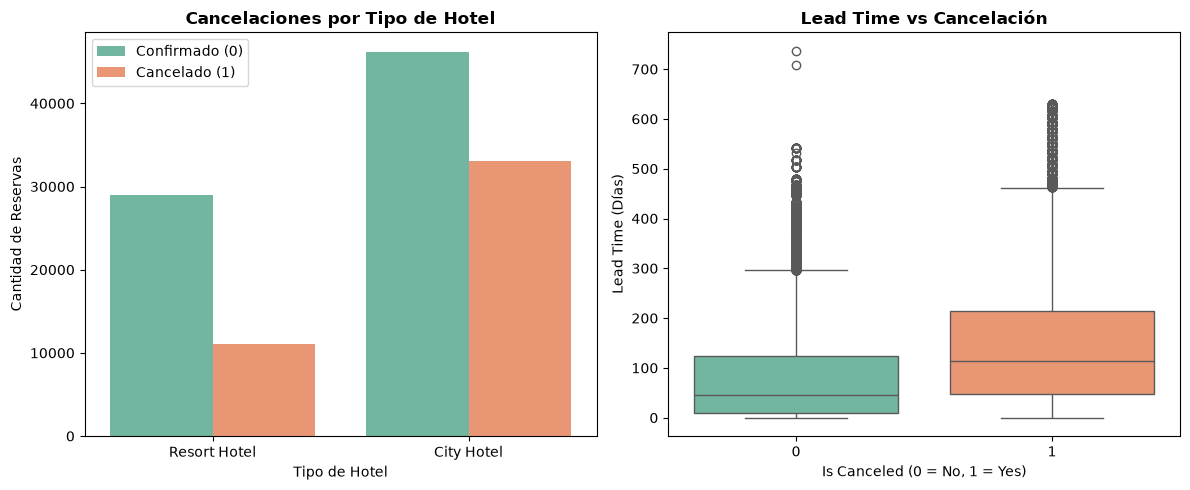

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных
df = pd.read_csv("../data/raw/hotel_bookings.csv")

# 2. Первичная диагностика
print(f"📊 Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок\n")

print("--- Пропущенные значения (Missing Values) ---")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\n--- Распределение целевого класса (is_canceled), % ---")
print((df['is_canceled'].value_counts(normalize=True) * 100).round(1))

# 3. Визуализация
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='hotel', hue='is_canceled', palette='Set2')
plt.title('Cancelaciones por Tipo de Hotel', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Hotel')
plt.ylabel('Cantidad de Reservas')
plt.legend(['Confirmado (0)', 'Cancelado (1)'])

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='is_canceled', y='lead_time',
            hue='is_canceled', palette='Set2', legend=False)
plt.title('Lead Time vs Cancelación', fontsize=12, fontweight='bold')
plt.xlabel('Is Canceled (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Días)')

plt.tight_layout()
plt.show()

Типы колонок и статистика:

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


 Сколько дубликатов:

In [6]:
df.duplicated().sum()

np.int64(31994)

Доля отмен по типам отелей:

In [7]:
df.groupby('hotel')['is_canceled'].mean()

hotel
City Hotel      0.417270
Resort Hotel    0.277634
Name: is_canceled, dtype: float64

Проверка колонки reservation_status:

In [8]:
pd.crosstab(df['is_canceled'], df['reservation_status'])

reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,75166,0
1,43017,0,1207
